# Task 1 — Funnel Trends, Seasonality & Channel Conversion

**Data source:** `data-cleaning/output/clean_daily.csv` only (built by `data-cleaning/clean.py`
from the raw briefing CSV; see `ASSUMPTIONS.md` for all cleaning decisions).

**Standing caveats applied throughout this notebook**

1. **Funnel-lag caveat (most important).** Funnel stages are *not* same-day cohorts: stage lag
   plus fractional multi-touch attribution mean MQP > Prospects in ~13% of daily rows,
   Demo > MQP in ~29%, Won > SQO in ~6%. Conversion rates are therefore computed at
   **monthly grain or coarser, never daily**, and read as period-level ratios, not cohort
   conversion of the same individuals.
2. **MQP tracking begins 2024-02-26** (one program 2024-01-03); MQP is identically zero for
   all programs before that. MQP is analyzed **from 2024-03 (first complete month) onward
   only**; FY24-vs-FY25 MQP totals are *not comparable* and are never presented as YoY.
3. **Excluded programs.** `ooh` and `paid_other` (zero cost, zero outcomes for the entire
   period) are excluded via `flag_excluded`.
4. **CTR hygiene.** 35 daily rows with clicks > impressions (`abm`, `paid_sponsorship`,
   `paid_awareness`; impression-tracking dropouts) are excluded from CTR calculations via
   `flag_clicks_gt_impressions`. Additionally, `paid_sponsorship` and `abm` show month-start
   click batch-dumps in 2025 (**possible tracking artifact**) and are kept out of any CTR
   narrative entirely.
5. **`website` demo-level shift at 2023-11** (~1,150 → ~340/month): treated as a *candidate
   tracking change (hypothesis)* — annotated wherever `website` appears; no website trend
   spanning that date is presented without this caveat.
6. **`event` / `webinar` daily outliers** are expected campaign bursts, not errors; monthly
   aggregation resolves them.
7. Fractional SQO / Won values come from fractional multi-touch attribution and are used as-is.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
import os

DECK = os.environ.get("DECK_FIGURES") == "1"   # deck variants: latte bg, no takeaway titles
FIG_DIR = REPO / "analysis" / "figures" / ("deck" if DECK else "")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(REPO / "data-cleaning" / "output" / "clean_daily.csv", parse_dates=["date"])
assert len(df) == 11926, "unexpected row count — rerun data-cleaning/clean.py"

d = df[~df["flag_excluded"]].copy()          # analysis universe
d["ym"] = d["date"].dt.to_period("M")

FUNNEL = ["prospects", "mqp", "demo", "sqo", "won"]
TOP = ["impressions", "clicks"]
MQP_START = "2024-03"                         # first complete month of MQP tracking

print(f"analysis rows: {len(d)} | programs: {d['program'].nunique()} | teams: {d['team'].nunique()}")


analysis rows: 10965 | programs: 15 | teams: 7


In [2]:
# ---- chart style (light mode; palette validated with dataviz validator) ----
INK, INK2, MUT = "#0b0b0b", "#52514e", "#898781"
GRID, BASE = "#e1e0d9", "#c3c2b7"
SURF = "#FFFBF4" if DECK else "#fcfcfb"        # deck variants sit on the latte slide bg
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUT, "ytick.color": MUT, "text.color": INK,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "ytick.left": False, "legend.frameon": False,
})

def spread(ys, gap):
    # nudge label y-positions apart so end-of-line labels never collide
    order = np.argsort(ys)
    out = np.array(ys, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < gap:
            out[b] = out[a] + gap
    return out

def footnote(fig, text, y=-0.02):
    if DECK:
        return                                  # slide-level footnotes replace these
    fig.text(0.01, y, text, fontsize=8.5, color=INK2, ha="left", va="top")

def takeaway_ax(ax, text, **kw):
    if not DECK:
        ax.set_title(text, **kw)                # slide title carries the takeaway in the deck

def takeaway_fig(fig, text, **kw):
    if not DECK:
        fig.suptitle(text, **kw)


## 1.1 Monthly funnel aggregation — total and by team

Top-funnel (`impressions`, `clicks`) is aggregated over **paid programs only** — non-paid
programs carry no impressions/clicks by construction. Bottom-funnel
(`prospects → mqp → demo → sqo → won`) covers all non-excluded programs. Monthly grain
per the funnel-lag caveat.


In [3]:
monthly_top = d[d.is_paid].groupby("ym")[TOP].sum()
monthly_bottom = d.groupby("ym")[FUNNEL].sum()
monthly_total = monthly_top.join(monthly_bottom).sort_index()

monthly_team = d.groupby(["ym", "team"])[FUNNEL].sum().reset_index()

fy = pd.concat([d[d.is_paid].groupby("fiscal_year")[TOP].sum(),
                d.groupby("fiscal_year")[FUNNEL].sum()], axis=1)
yoy = (fy.loc["FY25"] / fy.loc["FY24"] - 1) * 100
fy_summary = fy.T.assign(yoy_pct=yoy.round(1))
fy_summary.loc["mqp", "yoy_pct"] = np.nan   # MQP FY24 is a partial year -> not comparable
with pd.option_context("display.float_format", "{:,.1f}".format):
    print("Fiscal-year totals (FY = Jul-Jun) and YoY % (MQP YoY suppressed - tracking artifact):")
    print(fy_summary)

team_share = d.groupby("team")[FUNNEL].sum()
team_share_pct = (team_share / team_share.sum() * 100).round(1)
print()
print("Team share of total volume (%, full period):")
print(team_share_pct.sort_values("sqo", ascending=False))


Fiscal-year totals (FY = Jul-Jun) and YoY % (MQP YoY suppressed - tracking artifact):
fiscal_year            FY24            FY25  yoy_pct
impressions 5,526,262,916.0 5,723,418,610.0      3.6
clicks         35,724,187.0    35,187,602.0     -1.5
prospects         216,767.0       330,893.0     52.6
mqp                94,217.0       161,361.0      NaN
demo               59,265.0        65,071.0      9.8
sqo                19,323.4        26,178.1     35.5
won                 4,156.2         7,118.5     71.3

Team share of total volume (%, full period):
           prospects   mqp  demo   sqo   won
team                                        
paid            41.4  48.9  69.1  81.9  79.3
content          8.3   6.2   8.7   6.5   7.8
lifecycle        3.1   3.3   5.3   4.7   6.1
event           31.4  23.1   4.3   2.9   2.1
regional         9.6   7.8   2.6   2.5   2.2
website          5.4  10.1   9.2   1.0   2.2
social           0.8   0.5   0.7   0.5   0.3


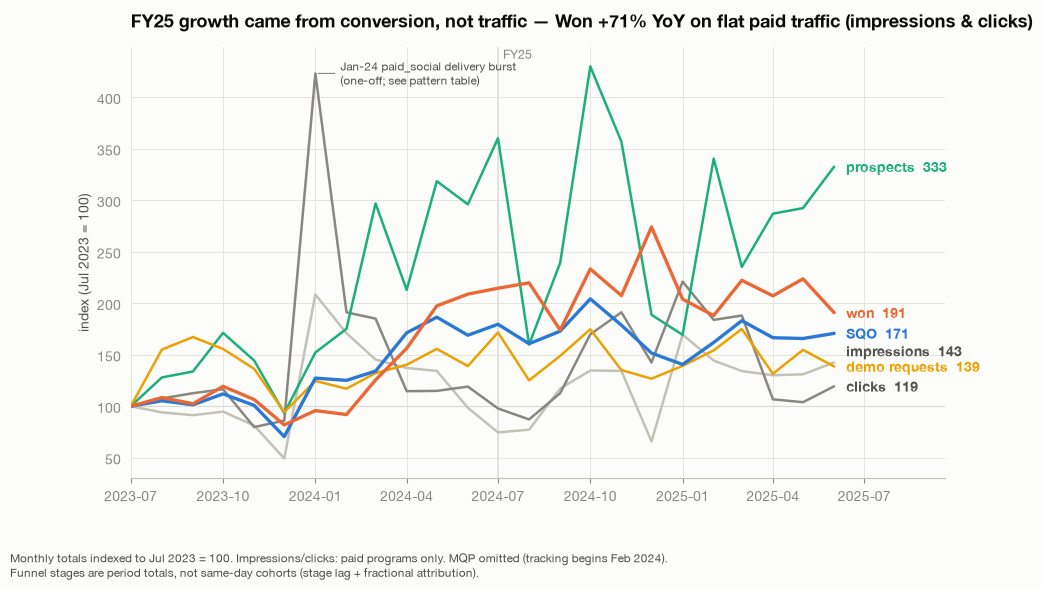

In [4]:
# ---- Figure 1: indexed funnel trend (design picked: indexed lines) ----
mt = monthly_total.copy()
mt.index = mt.index.to_timestamp()
idx = mt / mt.iloc[0] * 100

series = [("impressions", BASE, "impressions"), ("clicks", MUT, "clicks"),
          ("prospects", C_AQUA, "prospects"), ("demo", C_YELLOW, "demo requests"),
          ("sqo", C_BLUE, "SQO"), ("won", C_ORANGE, "won")]

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ends = spread([idx[c].iloc[-1] for c, _, _ in series], gap=15)
label_x = idx.index[-1] + pd.Timedelta(days=12)
for (col, color, label), y_end in zip(series, ends):
    lw = 2.4 if col in ("won", "sqo") else 1.8
    ax.plot(idx.index, idx[col], color=color, lw=lw, solid_capstyle="round")
    ax.text(label_x, y_end, f"{label}  {idx[col].iloc[-1]:.0f}", va="center",
            color=color if col not in ("impressions", "clicks") else INK2,
            fontsize=10, fontweight="bold")
ax.axhline(100, color=BASE, lw=0.8, zorder=0)
ax.axvline(pd.Timestamp("2024-07-01"), color=GRID, lw=1.2, zorder=0)
ax.text(pd.Timestamp("2024-07-06"), ax.get_ylim()[1], "FY25", color=MUT, fontsize=9, va="top")
ax.annotate("Jan-24 paid_social delivery burst\n(one-off; see appendix)" if DECK
            else "Jan-24 paid_social delivery burst\n(one-off; see pattern table)",
            xy=(pd.Timestamp("2024-01-01"), idx.loc["2024-01-01", "clicks"]),
            xytext=(18, -8), textcoords="offset points", fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUT, lw=0.8))
takeaway_ax(ax, "FY25 growth came from conversion, not traffic — Won +71% YoY on flat paid traffic (impressions & clicks)",
             fontsize=13, fontweight="bold", pad=14)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.Timedelta(days=110))
ax.set_ylabel("index (Jul 2023 = 100)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}"))
footnote(fig, "Monthly totals indexed to Jul 2023 = 100. Impressions/clicks: paid programs only. "
              "MQP omitted (tracking begins Feb 2024).\n"
              "Funnel stages are period totals, not same-day cohorts (stage lag + fractional attribution).")
fig.savefig(FIG_DIR / "fig1_indexed_funnel_trend.png")
plt.show()


## 1.2 Seasonality

Three lenses: **(a)** FY24-vs-FY25 overlay by fiscal month, **(b)** month-of-year deviation
from a centered 12-month rolling mean with a strict *both-years rule* — a pattern counts as
seasonal **only if the same calendar month deviates in the same direction in both observed
years** (|deviation| > 5%); one-year patterns are one-off events — and **(c)** day-of-week
profile (volumes only, never rates, so daily grain is acceptable here).

*Window caveat:* with 24 months of data, edge months use partial centered windows
(minimum 6 of 13 months). Deviations at the series edges can absorb some trend; the
both-years rule is the guard against over-reading them.


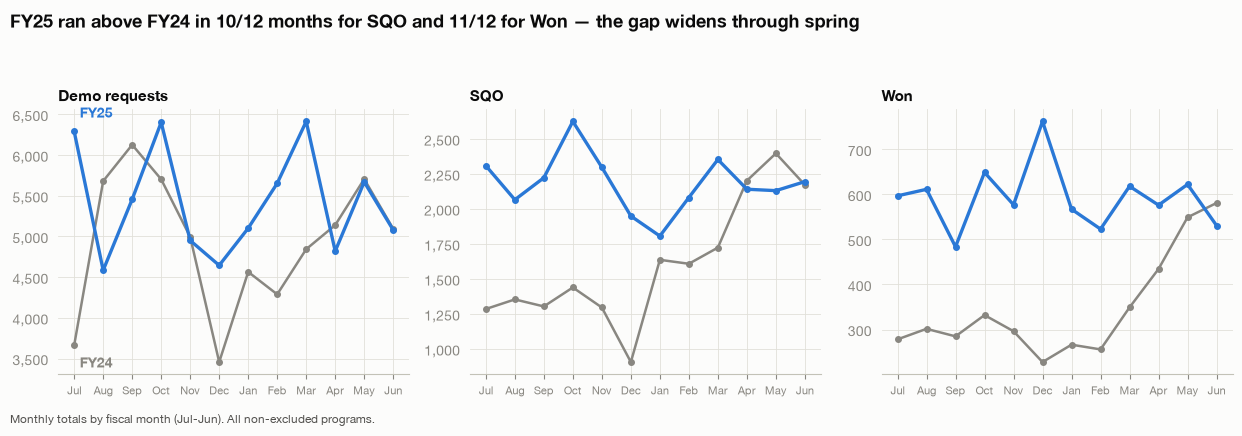

In [5]:
# ---- (a) YoY overlay: total, by fiscal month ----
FMONTHS = ["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun"]
ov = monthly_total.copy()
ov.index = ov.index.to_timestamp()
ov["fy"] = np.where(ov.index < "2024-07-01", "FY24", "FY25")
ov["fm"] = pd.Categorical([FMONTHS[(m - 7) % 12] for m in ov.index.month], categories=FMONTHS, ordered=True)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.1), sharex=True)
above = {}
for ax, (metric, label) in zip(axes, [("demo", "Demo requests"), ("sqo", "SQO"), ("won", "Won")]):
    piv = ov.pivot_table(index="fm", columns="fy", values=metric, observed=True)
    ax.plot(range(12), piv["FY24"], color=MUT, lw=1.8, marker="o", ms=4)
    ax.plot(range(12), piv["FY25"], color=C_BLUE, lw=2.4, marker="o", ms=4)
    above[metric] = int((piv["FY25"] > piv["FY24"]).sum())
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xticks(range(12), FMONTHS, fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
piv0 = ov.pivot_table(index="fm", columns="fy", values="demo", observed=True)
axes[0].annotate("FY25", xy=(0, piv0["FY25"].iloc[0]), xytext=(4, 10),
                 textcoords="offset points", color=C_BLUE, fontweight="bold")
axes[0].annotate("FY24", xy=(0, piv0["FY24"].iloc[0]), xytext=(4, -16),
                 textcoords="offset points", color=MUT, fontweight="bold")
takeaway_fig(fig, f"FY25 ran above FY24 in {above['sqo']}/12 months for SQO and {above['won']}/12 for Won "
             "— the gap widens through spring", fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.92))
footnote(fig, "Monthly totals by fiscal month (Jul-Jun). All non-excluded programs.", y=0.0)
fig.savefig(FIG_DIR / "fig2_yoy_overlay.png")
plt.show()


In [6]:
# ---- (a continued) YoY by largest teams (share of SQO: paid 81.9%, then content, lifecycle, event) ----
tm = monthly_team.copy()
tm["ts"] = tm["ym"].dt.to_timestamp()
tm["fy"] = np.where(tm["ts"] < "2024-07-01", "FY24", "FY25")
team_fy = tm.groupby(["team", "fy"])[["demo", "sqo", "won"]].sum().round(1)
team_fy_pct = (team_fy.xs("FY25", level="fy") / team_fy.xs("FY24", level="fy") - 1) * 100
print("FY24 vs FY25 by team (demo / sqo / won) and YoY %:")
out = team_fy.unstack("fy").swaplevel(axis=1).sort_index(axis=1)
for m in ["demo", "sqo", "won"]:
    out[("YoY %", m)] = team_fy_pct[m].round(1)
print(out.sort_values(("FY25", "sqo"), ascending=False).to_string())
print()
print("CAVEAT - website: demo-level shift at 2023-11 (~1,150 -> ~340/mo), candidate tracking")
print("change (hypothesis). Its demo YoY is NOT interpretable as real decline without a tagging audit.")


FY24 vs FY25 by team (demo / sqo / won) and YoY %:
fy          FY24                    FY25                  YoY %              
            demo      sqo     won   demo      sqo     won  demo    sqo    won
team                                                                         
paid       38399  15833.6  3155.1  47535  21437.9  5787.0  23.8   35.4   83.4
content     4364   1277.8   418.4   6505   1666.7   455.7  49.1   30.4    8.9
lifecycle   3114    682.7   206.8   3418   1463.7   479.0   9.8  114.4  131.6
event       2929    647.8   115.7   2393    651.4   120.5 -18.3    0.6    4.1
regional    1980    605.4   120.3   1306    519.0   129.5 -34.0  -14.3    7.6
website     8089    156.6   124.9   3402    317.9   123.0 -57.9  103.0   -1.5
social       390    119.5    15.0    512    121.5    23.8  31.3    1.7   58.7

CAVEAT - website: demo-level shift at 2023-11 (~1,150 -> ~340/mo), candidate tracking
change (hypothesis). Its demo YoY is NOT interpretable as real decline without a t

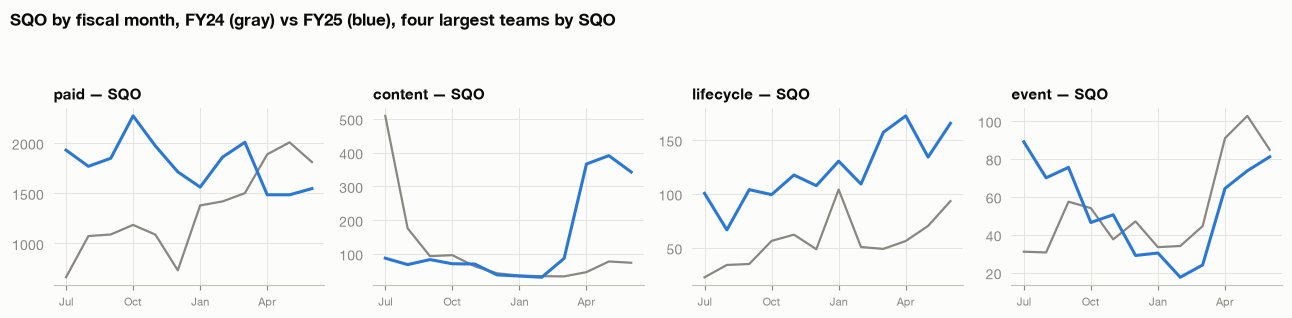

In [7]:
# ---- in-notebook view (not a deliverable figure): SQO YoY overlay for the 4 largest teams ----
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, team in zip(axes, ["paid", "content", "lifecycle", "event"]):
    piv = (tm[tm.team == team]
           .assign(fm=lambda x: pd.Categorical([FMONTHS[(m - 7) % 12] for m in x["ts"].dt.month],
                                               categories=FMONTHS, ordered=True))
           .pivot_table(index="fm", columns="fy", values="sqo", observed=True))
    ax.plot(range(12), piv["FY24"], color=MUT, lw=1.6)
    ax.plot(range(12), piv["FY25"], color=C_BLUE, lw=2.2)
    ax.set_title(f"{team} — SQO", fontsize=10.5, fontweight="bold")
    ax.set_xticks(range(0, 12, 3), [FMONTHS[i] for i in range(0, 12, 3)], fontsize=8)
fig.suptitle("SQO by fiscal month, FY24 (gray) vs FY25 (blue), four largest teams by SQO",
             fontsize=12, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()


In [8]:
# ---- (b) month-of-year deviation from centered 12-month rolling mean + both-years rule ----
def month_deviation(series):
    roll = series.rolling(13, center=True, min_periods=6).mean()
    return (series / roll - 1) * 100

dev_tables = {}
for metric in ["prospects", "demo", "sqo", "won"]:
    s = d.groupby("ym")[metric].sum().sort_index()
    dev = month_deviation(s)
    t = pd.DataFrame({"dev": dev})
    t["month"] = t.index.month
    t["obs"] = t.groupby("month").cumcount()          # 0 = first observed year, 1 = second
    piv = t.pivot_table(index="month", columns="obs", values="dev")
    piv.columns = ["year1", "year2"]
    piv["recurring"] = (np.sign(piv.year1) == np.sign(piv.year2)) & (piv.abs() > 5).all(axis=1)
    dev_tables[metric] = piv.round(1)

print("Month-of-year deviation (%) from centered 12m rolling mean — recurring = same sign both years, |dev|>5%:")
for metric, piv in dev_tables.items():
    rec = [f"{m:02d}" for m in piv.index[piv.recurring]]
    print(f"  {metric:10s} recurring months: {rec}")
print()
print("SQO detail:")
print(dev_tables["sqo"].to_string())


Month-of-year deviation (%) from centered 12m rolling mean — recurring = same sign both years, |dev|>5%:
  prospects  recurring months: ['01', '05', '06', '08', '09', '10', '12']
  demo       recurring months: ['01', '05', '10', '12']
  sqo        recurring months: ['12']
  won        recurring months: ['02', '08', '10']

SQO detail:
       year1  year2  recurring
month                         
1       -1.6  -17.2      False
2       -6.7   -4.1      False
3       -3.8    7.9      False
4       16.3   -1.6      False
5       22.4    0.5      False
6        8.1    4.8      False
7       -2.4   11.1      False
8        0.0   -2.2      False
9       -6.5    2.4      False
10      -2.5   19.2      False
11     -16.9    4.6      False
12     -43.7  -10.6       True


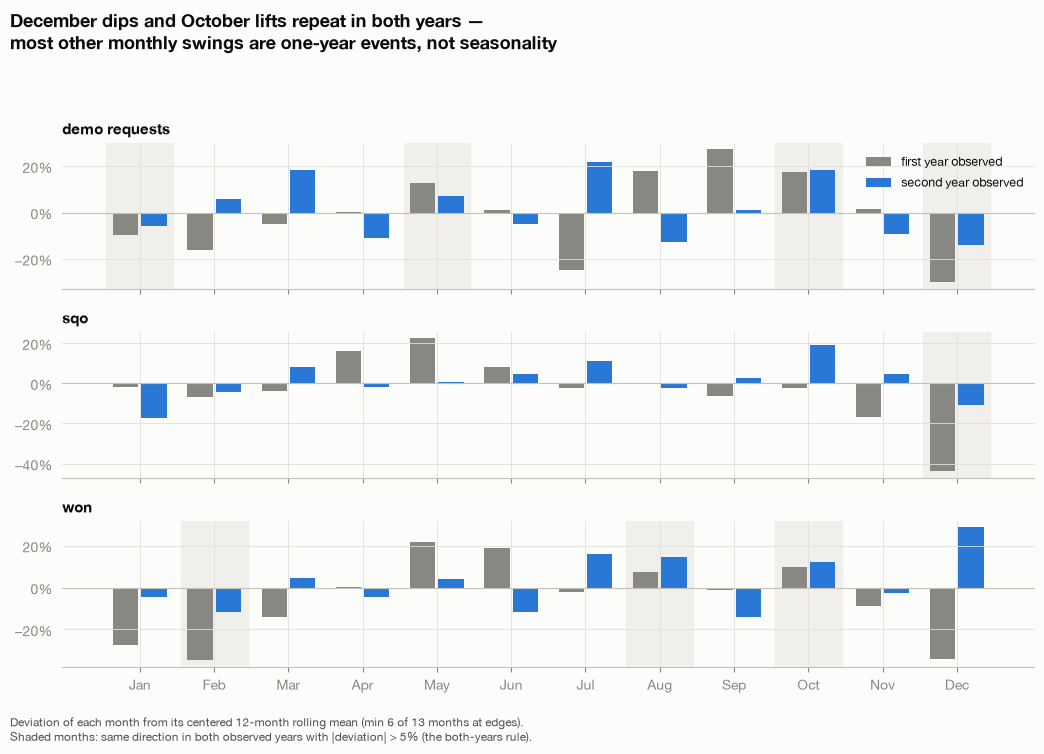

In [9]:
# ---- Figure 3: month-of-year deviations, both-years rule visualized ----
MONTH_LBL = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(3, 1, figsize=(10.5, 7.2), sharex=True)
for ax, metric in zip(axes, ["demo", "sqo", "won"]):
    piv = dev_tables[metric]
    x = np.arange(12)
    for m in x:
        if piv["recurring"].iloc[m]:
            ax.axvspan(m - 0.45, m + 0.45, color="#f0efec", zorder=0)
    ax.bar(x - 0.19, piv["year1"], width=0.34, color=MUT, label="first year observed")
    ax.bar(x + 0.19, piv["year2"], width=0.34, color=C_BLUE, label="second year observed")
    ax.axhline(0, color=BASE, lw=0.8)
    ax.set_title(metric if metric != "demo" else "demo requests", fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}%"))
axes[0].legend(loc="upper right", fontsize=9)
axes[-1].set_xticks(np.arange(12), MONTH_LBL)
takeaway_fig(fig, "December dips and October lifts repeat in both years —\n"
             "most other monthly swings are one-year events, not seasonality", fontsize=13,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.01, 1, 0.93))
footnote(fig, "Deviation of each month from its centered 12-month rolling mean (min 6 of 13 months at edges).\n"
              "Shaded months: same direction in both observed years with |deviation| > 5% (the both-years rule).", y=0.0)
fig.savefig(FIG_DIR / "fig3_month_of_year_deviation.png")
plt.show()


Mean daily volume by day of week (as % of Mon-Fri average):
     prospects   demo    sqo    won
Mon       82.0  107.4  102.7  101.7
Tue       90.8  103.8  105.2  113.6
Wed      110.9   99.9  104.2  103.1
Thu      115.0   97.5   99.3   91.4
Fri      101.3   91.4   88.5   90.2
Sat       19.0    3.2    2.8    8.4
Sun       25.2    3.8   10.1   10.0


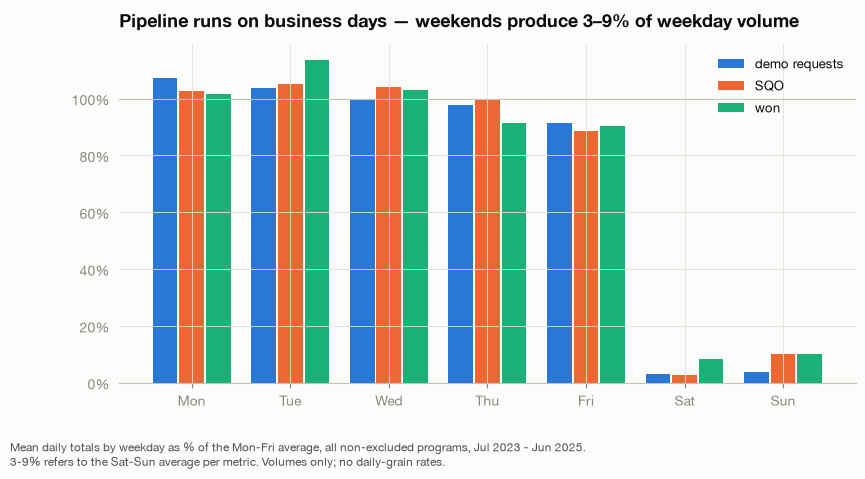

In [10]:
# ---- (c) day-of-week profile (volumes only — rates are never computed at daily grain) ----
daily = d.groupby("date")[["prospects", "demo", "sqo", "won"]].sum()
dow = daily.groupby(daily.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_avg = dow.iloc[:5].mean()
dow_pct = dow / weekday_avg * 100

print("Mean daily volume by day of week (as % of Mon-Fri average):")
print(dow_pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(7)
for off, (metric, color, label) in zip((-0.27, 0, 0.27),
        [("demo", C_BLUE, "demo requests"), ("sqo", C_ORANGE, "SQO"), ("won", C_AQUA, "won")]):
    ax.bar(x + off, dow_pct[metric], width=0.25, color=color, label=label)
ax.axhline(100, color=BASE, lw=0.8)
ax.set_xticks(x, dow.index)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}%"))
ax.legend(loc="upper right", fontsize=9.5)
takeaway_ax(ax, "Pipeline runs on business days — weekends produce 3–9% of weekday volume",
             fontsize=13, fontweight="bold", pad=12)
footnote(fig, "Mean daily totals by weekday as % of the Mon-Fri average, all non-excluded programs, "
              "Jul 2023 - Jun 2025.\n3-9% refers to the Sat-Sun average per metric. Volumes only; no daily-grain rates.")
fig.savefig(FIG_DIR / "fig4_day_of_week_profile.png")
plt.show()


### Candidate-pattern table

Labels: **recurring seasonal** (passes the both-years rule) · **one-off event** ·
**trend** · **possible tracking artifact**. Causes are *hypotheses*; the last column
states what evidence would confirm each. This data alone cannot establish causes.


In [11]:
patterns = pd.DataFrame([
    ["December dip", "recurring seasonal",
     "Dec below rolling mean both years: demo -30%/-14%, SQO -44%/-11%, prospects -50%/-33%",
     "Holiday slowdown in B2B buying committees",
     "Third year of data; industry benchmark curves"],
    ["October lift", "recurring seasonal",
     "Oct above rolling mean both years: demo +18%/+18%, won +10%/+12%, prospects +7%/+55%",
     "Autumn budget/planning season + campaign pushes",
     "Campaign calendar overlay; third year of data"],
    ["May-June lift (prospects)", "recurring seasonal",
     "May +28%/+6%, Jun +17%/+26% vs rolling mean, both years",
     "Fiscal year-end (Jun) push by sales/marketing",
     "Quota calendars; monthly spend pacing records"],
    ["January restart dip", "recurring seasonal",
     "Jan below rolling mean both years: prospects -23%/-40%, demo -9%/-6%",
     "Slow post-holiday restart of campaigns and buying",
     "Third year; campaign flight dates for January"],
    ["August prospect dip", "recurring seasonal (weak)",
     "Aug -7%/-41% both years — direction agrees, magnitude differs 6x",
     "Summer vacation effect, mainly in year 2",
     "Regional split (NH vs SH markets); third year"],
    ["Weekday/weekend cycle", "recurring seasonal",
     "Weekends at 3-9% of weekday volume for demo/SQO/won, stable across the full period",
     "B2B business-day behavior",
     "Holds by construction; no further evidence needed"],
    ["February Won dip", "recurring seasonal",
     "Feb Won below rolling mean both years: -35%/-12%",
     "Slow start-of-quarter closing after the Dec/Jan trough works through the funnel",
     "CRM close-date seasonality; third year of data"],
    ["Jan-2024 paid_social delivery burst", "one-off event",
     "Jan-24: impressions 660M (5.3x Dec), clicks 7.5M (7.5x Dec), CTR 1.13% (2-3x norm) on cost +94% ($4.0M); demo only 201->474",
     "A large January social campaign or cheap Q1 inventory buy",
     "Platform campaign records for Jan-Mar 2024"],
    ["Dec-2024 Won spike", "one-off event",
     "Won +29% vs rolling mean in Dec-24; Dec-23 was -34% — opposite sign, fails both-years rule",
     "Year-end close push or batched attribution credit",
     "CRM opportunity close-date audit for Dec-24"],
    ["Jul-2024 prospects/MQP burst", "one-off event",
     "Prospects +40% vs rolling mean in Jul-24 (Jul-23: -24%); event program MQP spike 2024-07-08 (8,610 in one day, 957x median)",
     "A single large event/conference in Jul-24",
     "Event calendar; per-program daily detail"],
    ["FY25 conversion-led growth", "trend",
     "SQO +35.5%, Won +71.3% YoY on impressions +3.6% / clicks -1.5%; gap widens through FY25",
     "Better qualification/targeting mix, growing brand-search share of spend",
     "Task 2 spend-mix analysis; incrementality testing"],
    ["paid_search CTR halved", "trend",
     "CTR 5.5% -> 2.8% FY24->FY25 while impressions +124% and clicks only +12.5%",
     "Deliberate reach expansion (broader match/inventory) diluting CTR",
     "Query/network mix report from the ad platform"],
    ["paid_awareness Mar-2025 ramp", "one-off event (flight)",
     "Monthly cost ~$133k -> ~$1.1M from 2025-03 (z=7.6 level shift); program is flighted by design",
     "A planned brand-awareness campaign flight",
     "Media plan / insertion orders"],
    ["MQP series start", "possible tracking artifact (confirmed structural)",
     "MQP identically zero for ALL programs before 2024-01-03; all programs start 2024-02-26",
     "MQP stage introduced to tracking in early 2024",
     "MAP/CRM field-creation date; definition docs"],
    ["website demo shift 2023-11", "possible tracking artifact",
     "Monthly demo ~1,150 -> ~340 at 2023-11 (z=5.6) with no matching shift in adjacent stages",
     "Tag/definition change on website demo tracking",
     "Web-analytics change log; tagging audit"],
    ["2025 month-start click dumps", "possible tracking artifact",
     "paid_sponsorship/abm clicks 200-1,100x median on month-firsts in 2025 (e.g. 296,928 on 2025-03-01)",
     "Vendor batch-loads monthly clicks on day 1",
     "Vendor reporting granularity; raw platform exports"],
], columns=["pattern", "label", "evidence", "hypothesis (NOT asserted)", "what would confirm it"])
with pd.option_context("display.max_colwidth", 110):
    print(patterns.to_string(index=False))


                            pattern                                             label                                                                                                                    evidence                                                       hypothesis (NOT asserted)                              what would confirm it
                       December dip                                recurring seasonal                                       Dec below rolling mean both years: demo -30%/-14%, SQO -44%/-11%, prospects -50%/-33%                                       Holiday slowdown in B2B buying committees      Third year of data; industry benchmark curves
                       October lift                                recurring seasonal                                        Oct above rolling mean both years: demo +18%/+18%, won +10%/+12%, prospects +7%/+55%                                 Autumn budget/planning season + campaign pushes      Campaign calendar overl

## 1.3 Channel conversion deep-dive: `paid_search`, `paid_brand_search`, `paid_social`

**Why these three.** They are the only programs with **full, always-on coverage of every
funnel step** impression → click → demo → SQO — and they form a clean strategic contrast:
*demand capture* (paid_search), *branded capture* (paid_brand_search, clicks from people
already searching for the brand), and *awareness/prospecting* (paid_social). Non-paid
channels are **ineligible by construction**: they carry no impressions or clicks, so an
impression→click comparison cannot be computed. Other paid programs were excluded because:
`abm`/`paid_sponsorship` show 2025 month-start click batch-dumps (possible tracking
artifact — no CTR narrative), `paid_awareness` is flighted (not always-on) with near-zero
bottom-funnel, and `listicle_leadbuy_listing` is a lead-buy with a structurally different
funnel.

> **Funnel-lag caveat (applies to every rate below).** Monthly rates are *period ratios* —
> e.g. this month's SQOs ÷ this month's demos — not cohort conversion of the same people:
> stage lag and fractional attribution shift credit across month boundaries. Rates are
> computed at monthly grain or coarser, never daily. CTR excludes the 35 flagged
> clicks>impressions rows (none fall in these three channels — verified below).


In [12]:
CH = ["paid_search", "paid_brand_search", "paid_social"]
CH_COLOR = {"paid_search": C_BLUE, "paid_brand_search": C_ORANGE, "paid_social": C_AQUA}
c3 = d[d.program.isin(CH)].copy()
print("flagged clicks>impressions rows inside the 3 channels:", int(c3.flag_clicks_gt_impressions.sum()))

ctr_safe = c3[~c3.flag_clicks_gt_impressions]      # identical to c3 here; kept as explicit hygiene
mch = (c3.groupby(["program", "ym"])[["demo", "sqo"]].sum()
         .join(ctr_safe.groupby(["program", "ym"])[["impressions", "clicks"]].sum()))
mch["ctr_pct"] = mch.clicks / mch.impressions * 100
mch["click_demo_pct"] = mch.demo / mch.clicks * 100
mch["demo_sqo_pct"] = mch.sqo / mch.demo * 100

fych = c3.groupby(["program", "fiscal_year"])[["impressions", "clicks", "demo", "sqo", "cost"]].sum()
fych["ctr_pct"] = fych.clicks / fych.impressions * 100
fych["click_demo_pct"] = fych.demo / fych.clicks * 100
fych["demo_sqo_pct"] = fych.sqo / fych.demo * 100
fych["cost_per_sqo"] = fych.cost / fych.sqo
print()
print("FY-level rates per channel (rates are FY aggregates, not averages of monthly rates):")
print(fych[["ctr_pct", "click_demo_pct", "demo_sqo_pct", "cost_per_sqo"]].round(2).to_string())


flagged clicks>impressions rows inside the 3 channels: 0

FY-level rates per channel (rates are FY aggregates, not averages of monthly rates):
                               ctr_pct  click_demo_pct  demo_sqo_pct  cost_per_sqo
program           fiscal_year                                                     
paid_brand_search FY24            5.43            0.56         53.35       3285.84
                  FY25            8.85            0.74         57.35       7212.57
paid_search       FY24            5.54            0.18         37.17       8801.22
                  FY25            2.79            0.23         38.92      10609.47
paid_social       FY24            0.57            0.02         25.92      35743.65
                  FY25            0.37            0.03         34.49      26826.22


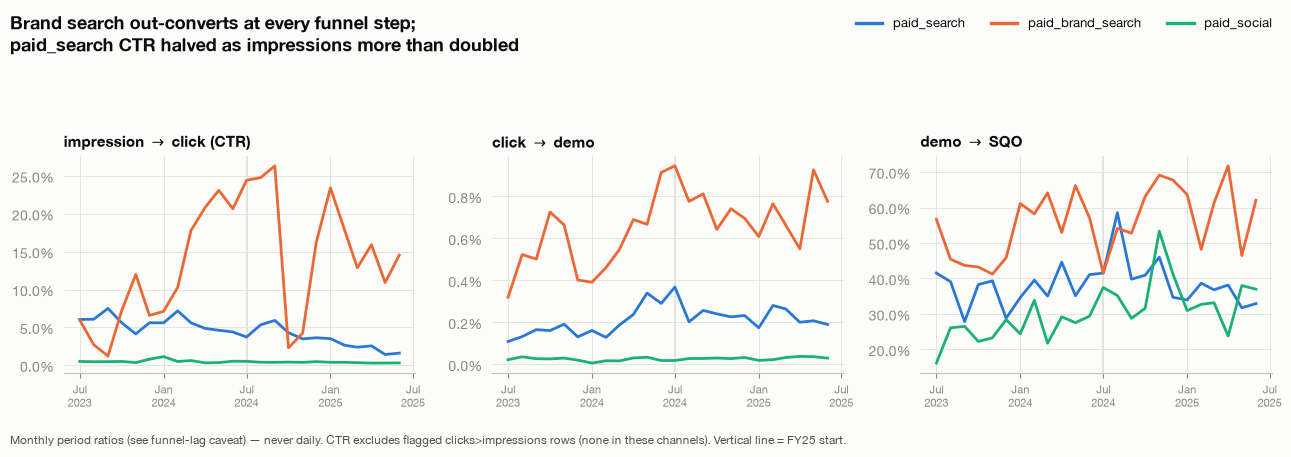

In [13]:
# ---- Figure 5: monthly rate trends per channel ----
import matplotlib.dates as mdates

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
titles = [("ctr_pct", "impression $\\rightarrow$ click (CTR)"),
          ("click_demo_pct", "click $\\rightarrow$ demo"),
          ("demo_sqo_pct", "demo $\\rightarrow$ SQO")]
for ax, (colname, title) in zip(axes, titles):
    for prog in CH:
        s = mch.loc[prog, colname]
        ax.plot(s.index.to_timestamp(), s.values, color=CH_COLOR[prog], lw=2.0)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.1f}%"))
    ax.axvline(pd.Timestamp("2024-07-01"), color=GRID, lw=1.1, zorder=0)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(axis="x", labelsize=8)
handles = [plt.Line2D([], [], color=CH_COLOR[p], lw=2.4) for p in CH]
fig.legend(handles, CH, loc="upper right", ncol=3, fontsize=9.5, bbox_to_anchor=(0.99, 1.0))
takeaway_fig(fig, "Brand search out-converts at every funnel step;\n"
             "paid_search CTR halved as impressions more than doubled", fontsize=13,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.02, 1, 0.87))
footnote(fig, "Monthly period ratios (see funnel-lag caveat) — never daily. CTR excludes flagged "
              "clicks>impressions rows (none in these channels). Vertical line = FY25 start.", y=0.0)
fig.savefig(FIG_DIR / "fig5_channel_rate_trends.png")
plt.show()


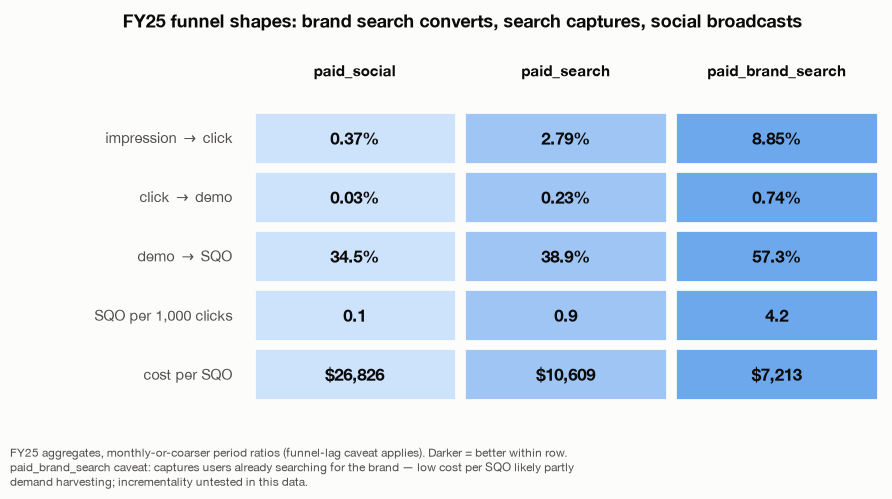

In [14]:
# ---- Figure 6: funnel shapes at a glance (FY25) ----
f25 = fych.xs("FY25", level="fiscal_year")
COL_ORDER = ["paid_social", "paid_search", "paid_brand_search"]  # matches slide sub-line order
rows = [
    ("impression $\\rightarrow$ click", [f25.loc[p, "ctr_pct"] for p in COL_ORDER], "{:.2f}%"),
    ("click $\\rightarrow$ demo", [f25.loc[p, "click_demo_pct"] for p in COL_ORDER], "{:.2f}%"),
    ("demo $\\rightarrow$ SQO", [f25.loc[p, "demo_sqo_pct"] for p in COL_ORDER], "{:.1f}%"),
    ("SQO per 1,000 clicks", [f25.loc[p, "sqo"] / f25.loc[p, "clicks"] * 1000 for p in COL_ORDER], "{:.1f}"),
    ("cost per SQO", [f25.loc[p, "cost_per_sqo"] for p in COL_ORDER], "${:,.0f}"),
]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec"]   # light sequential blue steps (low->high within row)

fig, ax = plt.subplots(figsize=(9.8, 4.6))
ax.set_xlim(0, 3.6); ax.set_ylim(0, len(rows) + 1); ax.axis("off"); ax.grid(False)
for j, p in enumerate(COL_ORDER):
    ax.text(0.6 + j + 0.5, len(rows) + 0.55, p, ha="center", fontsize=10.5, fontweight="bold", color=INK)
for i, (label, vals, fmt) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.text(0.52, y + 0.5, label, ha="right", va="center", fontsize=10.5, color=INK2)
    rank = np.argsort(np.argsort(vals))          # 0 = lowest within row
    if label == "cost per SQO":
        rank = 2 - rank                          # cheaper = better = darker
    for j, v in enumerate(vals):
        ax.add_patch(plt.Rectangle((0.6 + j + 0.02, y + 0.06), 0.96, 0.88,
                                   facecolor=SEQ[rank[j]], edgecolor=SURF, lw=2))
        ax.text(0.6 + j + 0.5, y + 0.5, fmt.format(v), ha="center", va="center",
                fontsize=12, fontweight="bold", color=INK)
takeaway_ax(ax, "FY25 funnel shapes: brand search converts, search captures, social broadcasts",
             fontsize=13, fontweight="bold", pad=16)
footnote(fig, "FY25 aggregates, monthly-or-coarser period ratios (funnel-lag caveat applies). Darker = better within row.\n"
              "paid_brand_search caveat: captures users already searching for the brand — low cost per SQO likely partly\n"
              "demand harvesting; incrementality untested in this data.", y=0.02)
fig.savefig(FIG_DIR / "fig6_funnel_shapes_fy25.png")
plt.show()


## 1.4 Findings — what the data SHOWS vs. recommendation candidates

### What the data shows (each number = aggregation it came from)

1. **Bottom-funnel outgrew top-funnel by an order of magnitude.** FY totals: impressions
   +3.6%, clicks −1.5%, vs prospects +52.6%, demo +9.8%, SQO +35.5% (19,323 → 26,178),
   Won +71.3% (4,156 → 7,119). *(FY sums, all non-excluded programs; MQP excluded —
   tracking artifact.)*
2. **The paid team owns the bottom funnel**: 81.9% of all SQO and 79.3% of Won
   (full-period sums); event generates 31.4% of prospects but only 2.9% of SQO.
3. **Two seasonal patterns pass the both-years rule**: a December dip (demo −30%/−14%,
   SQO −44%/−11% vs centered 12-mo rolling mean) and an October lift (demo +18%/+18%,
   won +10%/+12%). January (prospects/demo) and May–June (prospects) also recur;
   everything else observed is one-year-only. *(Monthly deviations from centered rolling mean.)*
4. **Weekends are near-zero for pipeline**: Sat–Sun run at 3–9% of the Mon–Fri average
   for demo/SQO/won (daily volume means, full period).
5. **paid_brand_search converts multiples above the others** (FY25 aggregates): CTR 8.9%
   vs 2.8% (search) / 0.4% (social); demo→SQO 57.4% vs 38.9% / 34.5%; 4.2 SQO per 1,000
   clicks vs 0.9 / 0.1.
6. **paid_brand_search efficiency worsened as spend tripled**: cost $23.7M → $69.1M
   (FY24→FY25) while SQO rose only +33% (7,213 → 9,585); cost per SQO $3,286 → $7,213.
   *(FY sums.)* ⚠ *Incrementality caveat below.*
7. **paid_search reach expanded, CTR halved**: impressions +124% (146M → 328M), clicks
   +12.5%, CTR 5.5% → 2.8%; click→demo actually improved (0.18% → 0.23%) and demo→SQO
   held (~38–39%), so the dilution is at the ad-serving stage, not in lead quality.
8. **paid_social is awareness-shaped but improving in the funnel it does have**:
   click→demo 0.02–0.03%; demo→SQO 25.9% → 34.5%; cost per Won $329k → $139k (FY sums;
   small absolute volumes: 1,181 → 1,468 SQO).
9. **MQP is unusable before 2024-03** (zero for all programs; tracking starts
   2024-02-26) — any MQP YoY or full-period MQP rate would be an artifact.

### Recommendation candidates (hypotheses for refinement — not conclusions)

- **Reallocate calendar, not just budget:** December's recurring dip and the October lift
  suggest shifting flighting/launches toward Sep–Oct and de-weighting late December.
  *(Would need: campaign-level pacing data to size the opportunity.)*
- **paid_brand_search: cap-and-test rather than scale further.** Observed low cost-per-SQO
  ($7.2k FY25) still leads all channels, **but** it captures users already searching for
  the brand — the low cost per SQO is likely **partly demand harvesting, and incrementality
  is untested in this data**. The FY25 cost-per-SQO doubling on 3x spend is consistent with
  saturating branded query volume. Candidate action: geo-holdout / incrementality test
  before further increases.
- **paid_search: revisit the reach expansion.** CTR halved as impressions doubled with
  flat clicks; if the expansion was deliberate, evaluate whether the incremental
  impressions produce SQOs (spend +82% for +51% SQO).
- **paid_social: judge as assist/awareness, not last-click SQO.** Its funnel improved
  (demo→SQO +8.6pp, cost/Won −58%) but volumes are small; MTA fractional credit
  understates/overstates unknown — brand-lift or holdout measurement would be the test.
- **Weekend spend hygiene:** if any always-on channels bid flat 7 days, weekday-weighted
  bidding is a low-risk efficiency candidate (weekends = 3–9% of pipeline volume).
- **Fix the tracking debts**: website demo definition (2023-11 shift), vendor click
  batch-dumps (sponsorship/abm), and document the MQP start date — all three currently
  contaminate naive trend reads.


## 1.5 Deliverable candidates

Figures exported to `analysis/figures/` (PNG, takeaway titles):

| file | takeaway title |
|---|---|
| `fig1_indexed_funnel_trend.png` | FY25 growth came from conversion, not traffic — Won +71% YoY on flat paid traffic (impressions & clicks) |
| `fig2_yoy_overlay.png` | FY25 ran above FY24 in 10/12 months for SQO and 11/12 for Won — the gap widens through spring |
| `fig3_month_of_year_deviation.png` | December dips and October lifts repeat in both years — most other swings are one-year events |
| `fig4_day_of_week_profile.png` | Pipeline runs on business days — weekends produce 3–9% of weekday volume |
| `fig5_channel_rate_trends.png` | Brand search out-converts at every funnel step; paid_search CTR halved as impressions doubled |
| `fig6_funnel_shapes_fy25.png` | FY25 funnel shapes: brand search converts, search captures, social broadcasts |

*(fig2 counts are computed in its cell and asserted in the verification cell; if data changes, titles fail loudly.)*

### Draft — what goes on the Task 1 slides (5 bullets)

1. FY25 delivered **+35% SQO and +71% Won on flat traffic** — growth came from conversion
   efficiency and mix, not from buying more impressions.
2. The **paid team produces ~80% of pipeline outcomes**; event feeds the top of funnel but
   converts thin — the funnel narrative should follow paid.
3. Seasonality is real but simple: a **December dip and an October lift recur in both
   years** (plus a business-day weekly cycle); plan flighting and targets around them —
   most other monthly swings were one-off events, not patterns.
4. **Channel funnel shapes differ by design**: brand search converts (57% demo→SQO,
   4.2 SQO/1k clicks), paid search captures demand at scale, paid social is
   awareness-shaped — compare channels within role, not on one metric.
5. **Brand search looks cheapest per SQO but is likely part demand-harvesting —
   incrementality untested**; its cost per SQO doubled as spend tripled. Recommend
   holdout/geo test before scaling further. *(Also: 3 tracking debts to fix — MQP start,
   website demo shift, vendor click dumps.)*


In [15]:
# ---- verification: every number cited in 1.4/1.5 re-derived here; hard-fails on drift ----
def close(a, b, tol=0.051):
    return abs(a - b) <= tol * max(1.0, abs(b))

assert close(fy_summary.loc["sqo", "yoy_pct"], 35.5, 0.01)
assert close(fy_summary.loc["won", "yoy_pct"], 71.3, 0.01)
assert close(fy_summary.loc["impressions", "yoy_pct"], 3.6, 0.01)
assert close(fy_summary.loc["clicks", "yoy_pct"], -1.5, 0.01)
assert close(fy_summary.loc["prospects", "yoy_pct"], 52.6, 0.01)
assert close(fy_summary.loc["demo", "yoy_pct"], 9.8, 0.01)
assert round(fy.loc["FY24", "sqo"]) == 19323 and round(fy.loc["FY25", "sqo"]) == 26178
assert close(fy.loc["FY24", "won"], 4156.2, 0.001) and close(fy.loc["FY25", "won"], 7118.5, 0.001)
assert close(team_share_pct.loc["paid", "sqo"], 81.9, 0.01)
assert close(team_share_pct.loc["paid", "won"], 79.3, 0.01)
assert close(team_share_pct.loc["event", "prospects"], 31.4, 0.01)
assert close(team_share_pct.loc["event", "sqo"], 2.9, 0.02)
assert (d[d.date < "2024-01-03"]["mqp"] == 0).all()
assert close(fych.loc[("paid_brand_search", "FY25"), "ctr_pct"], 8.85, 0.01)
assert close(fych.loc[("paid_search", "FY25"), "ctr_pct"], 2.79, 0.01)
assert close(fych.loc[("paid_search", "FY24"), "ctr_pct"], 5.54, 0.01)
assert close(fych.loc[("paid_brand_search", "FY25"), "demo_sqo_pct"], 57.35, 0.01)
assert close(fych.loc[("paid_brand_search", "FY25"), "cost_per_sqo"], 7213, 0.01)
assert close(fych.loc[("paid_brand_search", "FY24"), "cost_per_sqo"], 3286, 0.01)
assert close(fych.loc[("paid_search", "FY25"), "cost_per_sqo"], 10609, 0.01)
assert close(fych.loc[("paid_social", "FY25"), "demo_sqo_pct"], 34.49, 0.01)
b25 = fych.loc[("paid_brand_search", "FY25")]
assert close(b25["sqo"] / b25["clicks"] * 1000, 4.2, 0.02)
assert close(dev_tables["sqo"].loc[12, "year1"], -44, 0.05)
assert close(dev_tables["demo"].loc[10, "year1"], 18, 0.06) and close(dev_tables["demo"].loc[10, "year2"], 18, 0.06)
weekend_avg = dow_pct.loc[["Sat", "Sun"], ["demo", "sqo", "won"]].mean()
assert (weekend_avg >= 2.5).all() and (weekend_avg <= 9.5).all()
assert above == {"demo": 6, "sqo": 10, "won": 11}          # fig2 title counts
jan24_social = d[(d.program == "paid_social") & (d.year_month == "2024-01")]
assert close(jan24_social["clicks"].sum(), 7478432, 0.001)  # pattern-table burst evidence
assert close(dev_tables["won"].loc[2, "year1"], -35, 0.05) and close(dev_tables["won"].loc[2, "year2"], -12, 0.05)
print("All cited numbers verified against the cleaned data. OK")


All cited numbers verified against the cleaned data. OK
